# NIT6160 Data Warehousing and Mining — Project
## Health Dataset Analysis and Prediction: Cardiovascular Disease

**Dataset:** Cardiovascular Disease dataset (Kaggle, S. Ulianova), `cardio_train.csv` — 70,000 patient records, 11 features, binary target `cardio`.

**Scope:** the task classifies *recorded* presence of cardiovascular disease from a single examination. It does not predict future events or give a validated clinical risk score.

**Notebook structure**
0. Setup – configuration, reproducibility and helper functions (`load_data`, `quality_flags`, `clean`, `metrics`)
1. Task 1 – Dataset selection and description
2. Task 2 – Research questions
3. Task 3 – Data exploration (structure, missing data, descriptive statistics, central tendency and dispersion, data quality audit)
4. Data pre-processing (documented exclusion rules, feature engineering)
5. Task 4 – Data visualisation
6. Task 5 – Machine learning models, hyperparameter tuning and evaluation
7. Task 6 – Interpretation and conclusion

**To reproduce:** *Kernel → Restart & Run All*. The notebook finds `cardio_train.csv` in the current folder or any parent folder, uses a fixed seed and writes figures to `figures/` and metrics to `reports/notebook_results.json`.

## Task 1 – Dataset Selection

The Cardiovascular Disease dataset contains examination data for 70,000 patients. Every record contains three types of input features:

| Type | Feature | Column | Values |
|---|---|---|---|
| Objective (demographic) | Age | `age` | int, **days** |
| Objective (demographic) | Gender | `gender` | 1 = female, 2 = male |
| Objective | Height | `height` | cm |
| Objective | Weight | `weight` | kg |
| Examination (clinical) | Systolic blood pressure | `ap_hi` | mmHg |
| Examination (clinical) | Diastolic blood pressure | `ap_lo` | mmHg |
| Examination (clinical) | Cholesterol | `cholesterol` | 1 normal, 2 above normal, 3 well above normal |
| Examination (clinical) | Glucose | `gluc` | 1 normal, 2 above normal, 3 well above normal |
| Subjective (lifestyle) | Smoking | `smoke` | 0/1 |
| Subjective (lifestyle) | Alcohol intake | `alco` | 0/1 |
| Subjective (lifestyle) | Physical activity | `active` | 0/1 |
| **Target** | Presence of cardiovascular disease | `cardio` | 0/1 |

It covers all the variable groups required by the brief (demographics, clinical measurements, lifestyle factors and a health outcome) and is large enough for robust cross-validation. Cholesterol and glucose are ordinal categories, not laboratory concentrations. The country of origin, recruitment design and diagnostic definition are not documented.

## Task 2 – Research Questions

- **RQ1.** What are the most significant factors associated with the presence of cardiovascular disease (CVD)?
- **RQ2.** Is there a relationship between demographic factors (age, gender) and CVD?
- **RQ3.** How do lifestyle factors (smoking, alcohol intake, physical activity) relate to CVD?
- **RQ4.** Which variables contribute most to the prediction accuracy of machine learning models?
- **RQ5.** Can machine learning models (Logistic Regression, Random Forest, Neural Network) effectively predict CVD, and which offers the best accuracy–interpretability trade-off?

The literature survey that motivates these questions is in the written report.

## Setup
Imports, configuration and the helper functions used throughout the notebook. All constants (paths, seed, plausibility limits) are defined once here, so a change in one place applies everywhere.

In [1]:
import json
import os
import platform
import warnings
from pathlib import Path

# Silence two known, harmless scikit-learn messages (also in parallel worker processes)
QUIET = ["ignore:Inconsistent values", "ignore:`sklearn.utils.parallel.delayed`"]
os.environ["PYTHONWARNINGS"] = ",".join(QUIET)
for rule in QUIET:
    warnings.filterwarnings("ignore", message=rule.split(":", 1)[1])

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
from scipy import stats

from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, RandomizedSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, brier_score_loss,
                             ConfusionMatrixDisplay, RocCurveDisplay, classification_report)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")

SEED = 42
DATA_FILE = "cardio_train.csv"
# Works whether the notebook is opened from the project root or a sub-folder
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / DATA_FILE).exists())
FIG_DIR = ROOT / "figures"
REPORT_DIR = ROOT / "reports"
FIG_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)

RAW_FEATURES = ["age", "gender", "height", "weight", "ap_hi", "ap_lo", "cholesterol", "gluc", "smoke", "alco", "active"]
TARGET = "cardio"
# Clinical plausibility limits (inclusive) used to flag and exclude impossible values
LIMITS = {"ap_hi": (80, 250), "ap_lo": (40, 160), "height": (120, 220), "weight": (30, 200), "bmi": (10, 70)}

VERSIONS = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
            "scikit-learn": sklearn.__version__, "scipy": scipy.__version__,
            "matplotlib": matplotlib.__version__, "seaborn": sns.__version__}
print("Project root:", ROOT)
print(" | ".join(f"{k} {v}" for k, v in VERSIONS.items()))

Project root: /home/sunil/opt/data warehouse/project
python 3.14.7 | pandas 3.0.6 | numpy 2.5.3 | scikit-learn 1.9.1 | scipy 1.18.1 | matplotlib 3.11.2 | seaborn 0.13.2


In [2]:
def save(name):
    """Save the current figure to figures/ and show it."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def load_data(path=None):
    """Load the semicolon-separated file and validate schema, target and ids before any analysis."""
    df = pd.read_csv(path or ROOT / DATA_FILE, sep=";")
    expected = {"id", TARGET, *RAW_FEATURES}
    if set(df.columns) != expected:
        raise ValueError(f"Unexpected schema: {sorted(df.columns)}")
    non_numeric = [c for c in RAW_FEATURES if not pd.api.types.is_numeric_dtype(df[c])]
    if non_numeric:
        raise ValueError(f"Non-numeric predictors (check parsing / separator): {non_numeric}")
    if df[TARGET].isna().any() or not set(df[TARGET].unique()) <= {0, 1}:
        raise ValueError("Target must contain only 0 and 1")
    if df["id"].duplicated().any():
        raise ValueError("Duplicate patient ids found")
    return df


BP_RULES = ["nonpositive_blood_pressure", "systolic_outside_80_250", "diastolic_outside_40_160", "diastolic_above_systolic"]
BODY_RULES = ["height_outside_120_220", "weight_outside_30_200", "bmi_outside_10_70"]
CODE_RULES = ["invalid_gender_code", "invalid_cholesterol_or_glucose_code", "invalid_binary_predictor"]

def quality_flags(df):
    """One boolean column per data-quality rule; True means the row breaks that rule."""
    bmi = df.weight / (df.height / 100) ** 2
    return pd.DataFrame({
        "nonpositive_blood_pressure": (df.ap_hi <= 0) | (df.ap_lo <= 0),
        "systolic_outside_80_250": ~df.ap_hi.between(*LIMITS["ap_hi"]),
        "diastolic_outside_40_160": ~df.ap_lo.between(*LIMITS["ap_lo"]),
        "diastolic_above_systolic": df.ap_lo > df.ap_hi,
        "height_outside_120_220": ~df.height.between(*LIMITS["height"]),
        "weight_outside_30_200": ~df.weight.between(*LIMITS["weight"]),
        "bmi_outside_10_70": ~bmi.between(*LIMITS["bmi"]),
        "invalid_gender_code": ~df.gender.isin([1, 2]),
        "invalid_cholesterol_or_glucose_code": ~df.cholesterol.isin([1, 2, 3]) | ~df.gluc.isin([1, 2, 3]),
        "invalid_binary_predictor": ~df[["smoke", "alco", "active"]].isin([0, 1]).all(axis=1),
    }, index=df.index)


def clean(df):
    """Apply the documented exclusion rules and feature engineering. Returns (clean_df, exclusion_log)."""
    log = {"original rows": len(df)}
    out = df.drop(columns="id").drop_duplicates()
    log["exact duplicate records removed"] = log["original rows"] - len(out)

    flags = quality_flags(out)
    bad_bp = flags[BP_RULES].any(axis=1)
    bad_body = flags[BODY_RULES].any(axis=1) & ~bad_bp
    bad_code = flags[CODE_RULES].any(axis=1) & ~bad_bp & ~bad_body
    log["implausible blood pressure removed"] = int(bad_bp.sum())
    log["implausible height/weight/BMI removed"] = int(bad_body.sum())
    log["invalid category codes removed"] = int(bad_code.sum())
    out = out[~flags.any(axis=1)].copy()

    # Identical predictor profiles share a group id so they never fall in both train and test
    out["profile_id"] = pd.util.hash_pandas_object(out[RAW_FEATURES], index=False).values
    out["age_years"] = (out.age / 365.25).round(1)
    out["bmi"] = (out.weight / (out.height / 100) ** 2).round(2)
    out["pulse_pressure"] = out.ap_hi - out.ap_lo
    out["male"] = (out.gender == 2).astype(int)
    out = out.drop(columns=["age", "gender"]).reset_index(drop=True)

    # Post-conditions: the rules really hold on the output
    for col, (lo, hi) in LIMITS.items():
        assert out[col].between(lo, hi).all(), col
    assert (out.ap_hi >= out.ap_lo).all() and not out.isna().any().any()

    log["final rows"] = len(out)
    log["percent retained"] = round(len(out) / log["original rows"] * 100, 2)
    return out, log


def metrics(y_true, proba, threshold=0.5):
    """Classification metrics at a fixed threshold plus threshold-free ranking/calibration metrics."""
    pred = (proba >= threshold).astype(int)
    return {"Accuracy": accuracy_score(y_true, pred), "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred, zero_division=0), "F1": f1_score(y_true, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_true, proba), "Avg precision": average_precision_score(y_true, proba),
            "Brier": brier_score_loss(y_true, proba)}

## Task 3 – Data Exploration
### 3.1 Load and examine the dataset

In [3]:
df_raw = load_data()
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (70000, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


### 3.2 Missing data and duplicates

In [5]:
missing = pd.DataFrame({"missing": df_raw.isna().sum(), "percent": (df_raw.isna().mean() * 100).round(2)})
print(missing.T)
profiles = df_raw.groupby(RAW_FEATURES)[TARGET].nunique()
print("\nDuplicate records (ignoring id):", df_raw.drop(columns="id").duplicated().sum())
print("Duplicate predictor profiles:", df_raw.duplicated(RAW_FEATURES).sum())
print("Profiles with conflicting targets (same inputs, different label):", (profiles > 1).sum())

          id  age  gender  height  weight  ap_hi  ap_lo  cholesterol  gluc  smoke  alco  active  cardio
missing  0.0  0.0     0.0     0.0     0.0    0.0    0.0          0.0   0.0    0.0   0.0     0.0     0.0
percent  0.0  0.0     0.0     0.0     0.0    0.0    0.0          0.0   0.0    0.0   0.0     0.0     0.0

Duplicate records (ignoring id): 24
Duplicate predictor profiles: 41
Profiles with conflicting targets (same inputs, different label): 17


There are **no missing (NaN) values**. A few predictor profiles appear more than once, and some of them carry *different* labels. These are handled in the split (Task 5b) so that identical inputs never leak between training and test data. The summary statistics below also show that the data contains impossible values, which are a hidden data quality problem.

### 3.3 Descriptive statistics

In [6]:
df = df_raw.drop(columns="id").copy()
df["age_years"] = (df["age"] / 365.25).round(1)
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,70000.0,19468.87,2467.25,10798.0,17664.0,19703.0,21327.0,23713.0
gender,70000.0,1.35,0.48,1.0,1.0,1.0,2.0,2.0
height,70000.0,164.36,8.21,55.0,159.0,165.0,170.0,250.0
weight,70000.0,74.21,14.40,10.0,65.0,72.0,82.0,200.0
ap_hi,70000.0,128.82,154.01,-150.0,120.0,120.0,140.0,16020.0
ap_lo,70000.0,96.63,188.47,-70.0,80.0,80.0,90.0,11000.0
cholesterol,70000.0,1.37,0.68,1.0,1.0,1.0,2.0,3.0
gluc,70000.0,1.23,0.57,1.0,1.0,1.0,1.0,3.0
smoke,70000.0,0.09,0.28,0.0,0.0,0.0,0.0,1.0
alco,70000.0,0.05,0.23,0.0,0.0,0.0,0.0,1.0


### 3.4 Central tendency and dispersion

In [7]:
num_cols = ["age_years", "height", "weight", "ap_hi", "ap_lo"]
ct = pd.DataFrame({
    "mean": df[num_cols].mean(),
    "median": df[num_cols].median(),
    "mode": df[num_cols].mode().iloc[0],
    "variance": df[num_cols].var(),
    "std": df[num_cols].std(),
    "min": df[num_cols].min(),
    "max": df[num_cols].max(),
    "IQR": df[num_cols].quantile(0.75) - df[num_cols].quantile(0.25),
    "skewness": df[num_cols].skew(),
    "kurtosis": df[num_cols].kurt(),
}).round(2)
ct

,mean,median,mode,variance,std,min,max,IQR,skewness,kurtosis
age_years,53.30,53.9,56.0,45.63,6.76,29.6,64.9,10.0,-0.31,-0.82
height,164.36,165.0,165.0,67.41,8.21,55.0,250.0,11.0,-0.64,7.94
weight,74.21,72.0,65.0,207.24,14.40,10.0,200.0,17.0,1.01,2.59
ap_hi,128.82,120.0,120.0,23719.52,154.01,-150.0,16020.0,20.0,85.30,7580.07
ap_lo,96.63,80.0,80.0,35521.89,188.47,-70.0,11000.0,10.0,32.11,1425.91


In [8]:
cat_cols = ["gender", "cholesterol", "gluc", "smoke", "alco", "active", "cardio"]
cat_summary = pd.concat({c: df[c].value_counts().sort_index().to_frame("count")
                         .assign(percent=lambda t: (t["count"] / len(df) * 100).round(1)) for c in cat_cols})
cat_summary

count  percent
gender      1  45530     65.0
            2  24470     35.0
cholesterol 1  52385     74.8
            2   9549     13.6
            3   8066     11.5
gluc        1  59479     85.0
            2   5190      7.4
            3   5331      7.6
smoke       0  63831     91.2
            1   6169      8.8
alco        0  66236     94.6
            1   3764      5.4
active      0  13739     19.6
            1  56261     80.4
cardio      0  35021     50.0
            1  34979     50.0

**Observations**
- The target is **balanced** (≈50% / 50%), so accuracy is a meaningful metric and resampling is not needed.
- Women (gender = 1) make up about 65% of records. Gender = 2 has the higher mean height, which confirms that 2 = male.
- `ap_hi` and `ap_lo` have extreme variance (std > 150 mmHg) and kurtosis, with maxima of 16,020 and 11,000 mmHg and negative minima. These are clearly data entry errors.
- `height` (55–250 cm) and `weight` (10–200 kg) also contain implausible values.

### 3.5 Data quality audit

In [9]:
flags = quality_flags(df_raw)
audit = flags.sum().to_frame("rows")
audit["percent"] = (audit.rows / len(df_raw) * 100).round(2)
print(audit)
print("\nRows breaking at least one rule:", flags.any(axis=1).sum())

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

print("\nFor comparison, IQR (1.5×) outlier counts:")
print(pd.Series({c: iqr_outliers(df[c]) for c in num_cols}))

                                     rows  percent
nonpositive_blood_pressure             29     0.04
systolic_outside_80_250               247     0.35
diastolic_outside_40_160             1025     1.46
diastolic_above_systolic             1234     1.76
height_outside_120_220                 53     0.08
weight_outside_30_200                   7     0.01
bmi_outside_10_70                      42     0.06
invalid_gender_code                     0     0.00
invalid_cholesterol_or_glucose_code     0     0.00
invalid_binary_predictor                0     0.00

Rows breaking at least one rule: 1393

For comparison, IQR (1.5×) outlier counts:
age_years       4
height        519
weight       1819
ap_hi        1435
ap_lo        4632
dtype: int64


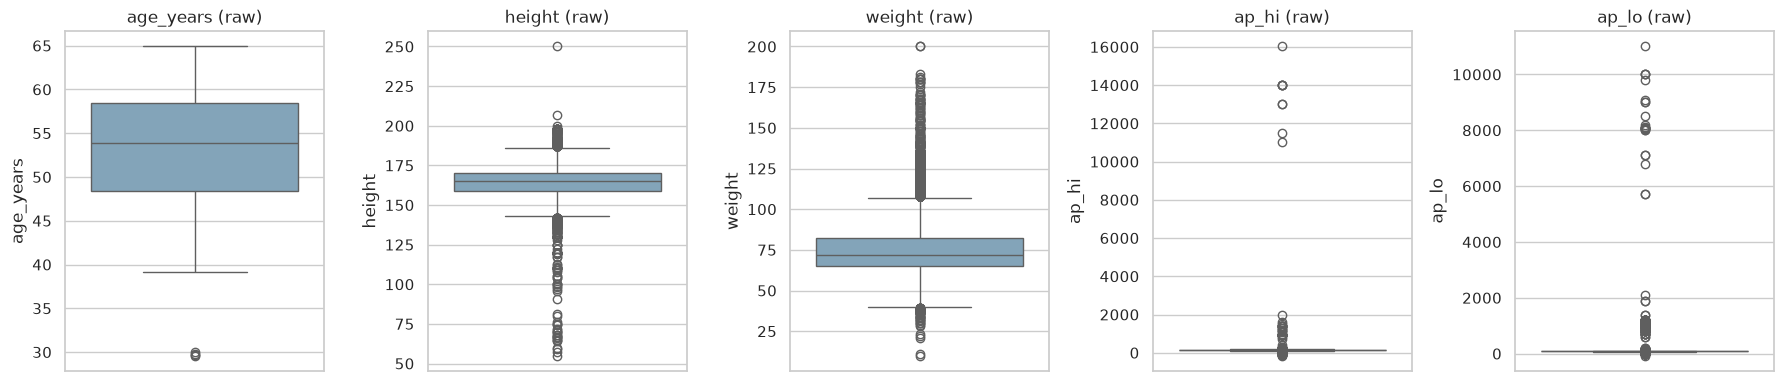

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(y=df[c], ax=ax, color="#7aa6c2")
    ax.set_title(f"{c} (raw)")
save("01_boxplots_raw")

## Data Pre-processing

The exclusion rules are fixed in advance (`LIMITS` in Setup) from clinical plausibility, **not** chosen to improve model scores:
1. Remove exact duplicate records.
2. Remove **physiologically implausible** blood pressure readings: non-positive values, systolic outside 80–250 mmHg, diastolic outside 40–160 mmHg, or diastolic above systolic. A plain IQR rule was rejected because it would also remove genuine hypertensive patients, who carry the signal we want to model.
3. Remove implausible anthropometrics: height outside 120–220 cm, weight outside 30–200 kg, BMI outside 10–70.
4. Feature engineering: `age_years`, **BMI** = weight / height², **pulse pressure** = systolic − diastolic, and `gender` recoded to `male` (0/1).
5. Scale features with `StandardScaler` inside a Pipeline (Task 5). Fitting the scaler inside cross-validation avoids data leakage.

`clean()` asserts that every rule holds on its output, and it returns a log of how many rows each rule removed.

In [11]:
clean_df, exclusion_log = clean(df_raw)
print(pd.Series(exclusion_log).to_string())
print("\nTarget balance after cleaning:", clean_df[TARGET].value_counts(normalize=True).round(3).to_dict())
clean_df.drop(columns="profile_id").describe().T.round(2)

original rows                            70000.00
exact duplicate records removed             24.00
implausible blood pressure removed        1334.00
implausible height/weight/BMI removed       59.00
invalid category codes removed               0.00
final rows                               68583.00
percent retained                            97.98

Target balance after cleaning: {0: 0.505, 1: 0.495}


,count,mean,std,min,25%,50%,75%,max
height,68583.0,164.42,7.91,120.00,159.00,165.00,170.00,207.00
weight,68583.0,74.12,14.29,30.00,65.00,72.00,82.00,200.00
ap_hi,68583.0,126.68,16.68,80.00,120.00,120.00,140.00,240.00
ap_lo,68583.0,81.31,9.43,40.00,80.00,80.00,90.00,160.00
cholesterol,68583.0,1.36,0.68,1.00,1.00,1.00,2.00,3.00
gluc,68583.0,1.23,0.57,1.00,1.00,1.00,1.00,3.00
smoke,68583.0,0.09,0.28,0.00,0.00,0.00,0.00,1.00
alco,68583.0,0.05,0.22,0.00,0.00,0.00,0.00,1.00
active,68583.0,0.80,0.40,0.00,1.00,1.00,1.00,1.00
cardio,68583.0,0.49,0.50,0.00,0.00,0.00,1.00,1.00


## Task 4 – Data Visualisation
### 4.1 Distributions (histograms)

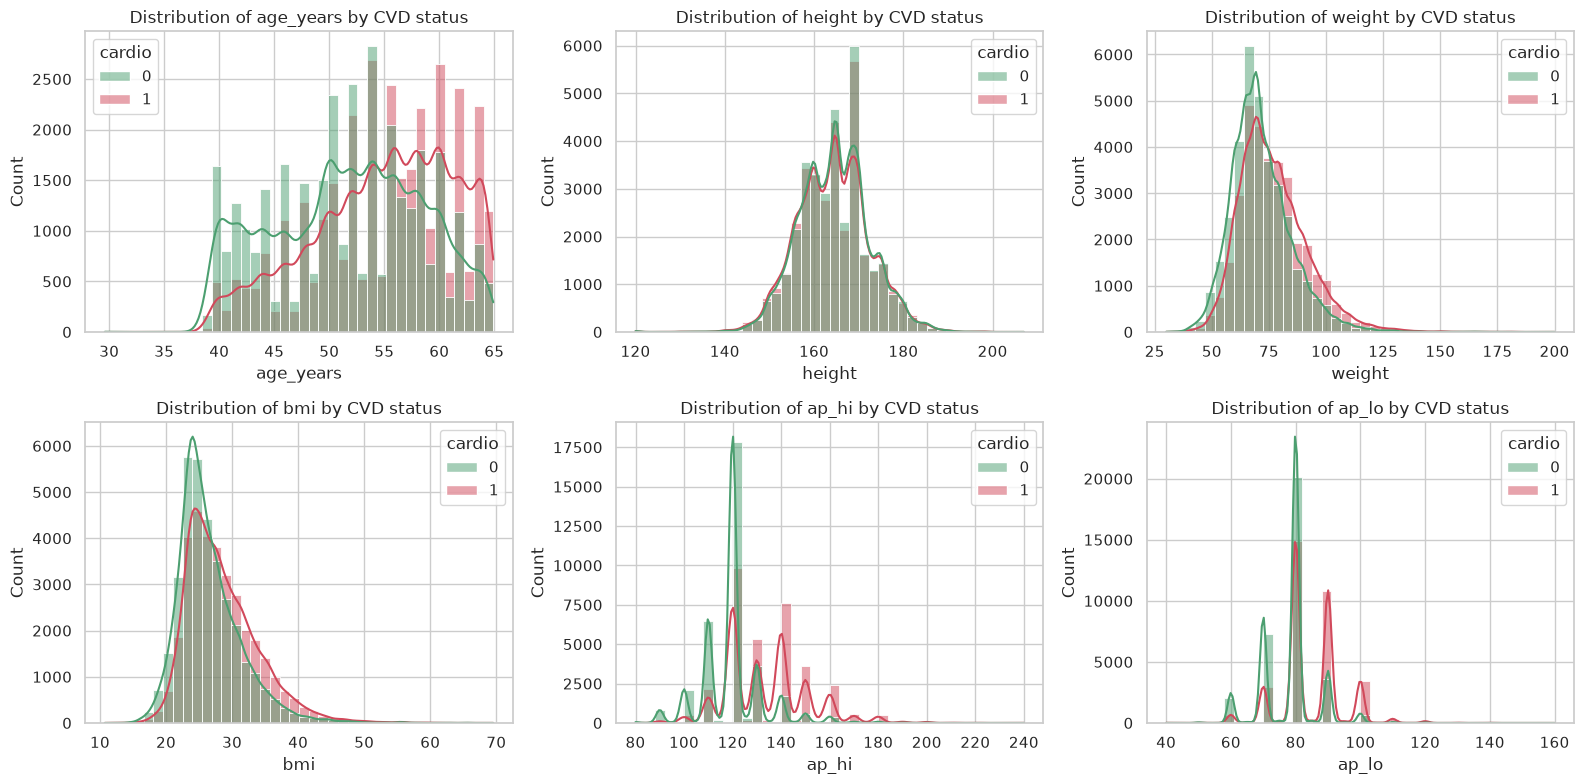

In [12]:
PALETTE = {0: "#4c9f70", 1: "#d1495b"}
plot_num = ["age_years", "height", "weight", "bmi", "ap_hi", "ap_lo"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), plot_num):
    sns.histplot(data=clean_df, x=c, hue=TARGET, bins=40, kde=True, ax=ax, palette=PALETTE, alpha=0.5)
    ax.set_title(f"Distribution of {c} by CVD status")
save("02_histograms")

### 4.2 Box plots by target (cleaned data)

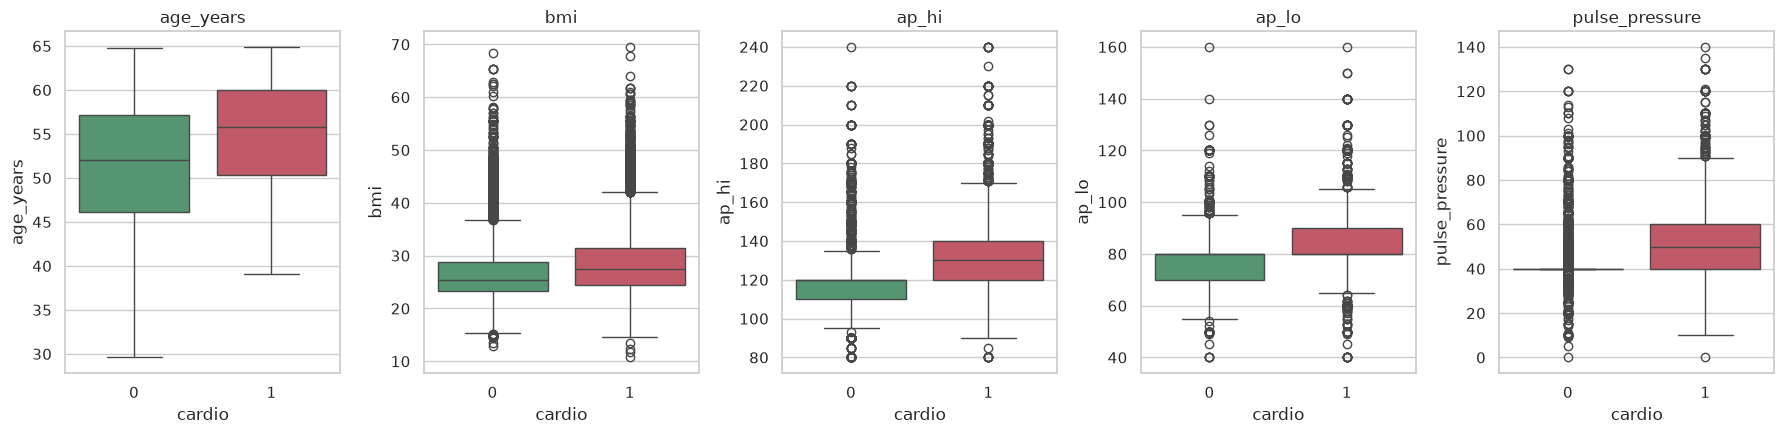

In [13]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4.5))
for ax, c in zip(axes, ["age_years", "bmi", "ap_hi", "ap_lo", "pulse_pressure"]):
    sns.boxplot(data=clean_df, x=TARGET, y=c, hue=TARGET, ax=ax, palette=list(PALETTE.values()), legend=False)
    ax.set_title(c)
save("03_boxplots_by_target")

### 4.3 Categorical and lifestyle factors vs CVD prevalence

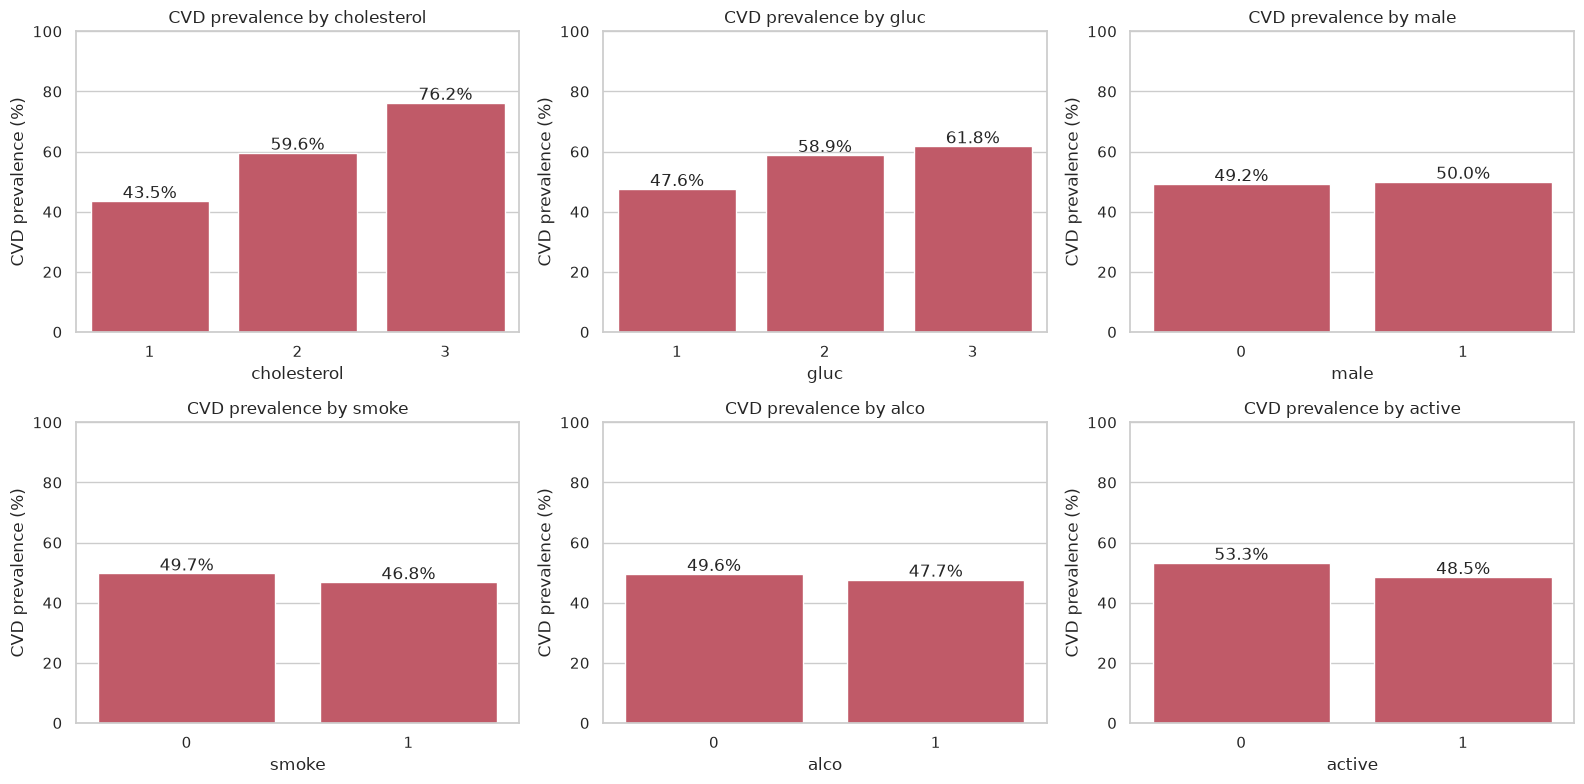

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), ["cholesterol", "gluc", "male", "smoke", "alco", "active"]):
    rate = clean_df.groupby(c)[TARGET].mean() * 100
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color="#d1495b")
    for i, v in enumerate(rate.values):
        ax.text(i, v + 1, f"{v:.1f}%", ha="center")
    ax.set_ylim(0, 100); ax.set_ylabel("CVD prevalence (%)"); ax.set_title(f"CVD prevalence by {c}")
save("04_prevalence_categorical")

### 4.4 Trend: CVD prevalence by age (line graph)

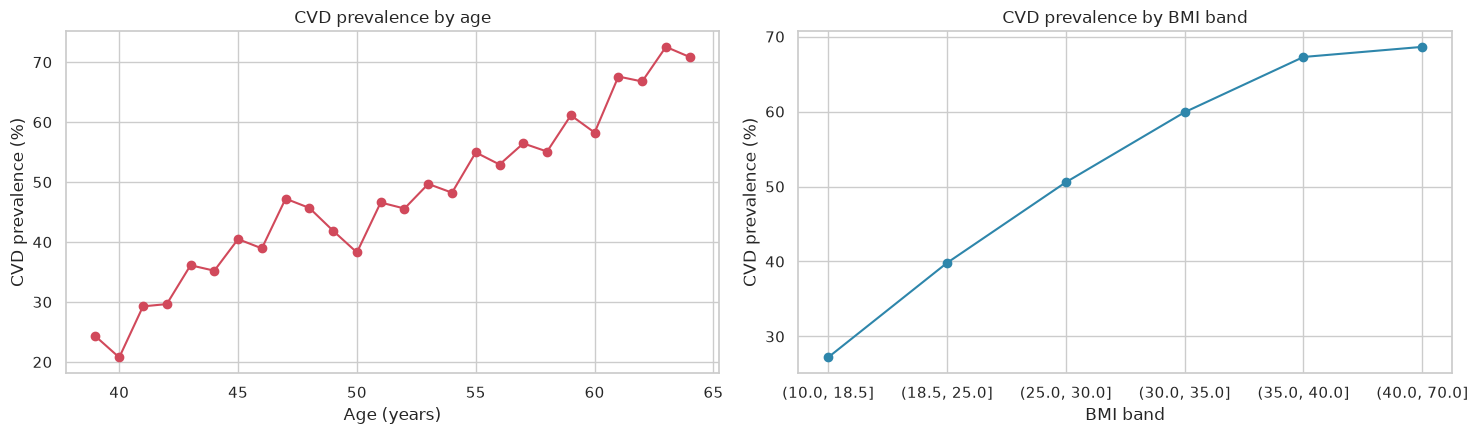

In [15]:
age_rate = clean_df.assign(age_int=clean_df.age_years.astype(int)).groupby("age_int")[TARGET].agg(["mean", "size"])
age_rate = age_rate[age_rate["size"] >= 100]
bmi_rate = clean_df.assign(bmi_band=pd.cut(clean_df.bmi, [10, 18.5, 25, 30, 35, 40, 70])).groupby("bmi_band", observed=True)[TARGET].mean()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(age_rate.index, age_rate["mean"] * 100, marker="o", color="#d1495b")
axes[0].set(xlabel="Age (years)", ylabel="CVD prevalence (%)", title="CVD prevalence by age")
axes[1].plot(bmi_rate.index.astype(str), bmi_rate.values * 100, marker="o", color="#2e86ab")
axes[1].set(xlabel="BMI band", ylabel="CVD prevalence (%)", title="CVD prevalence by BMI band")
save("05_line_age_bmi")

### 4.5 Relationships: scatter plots

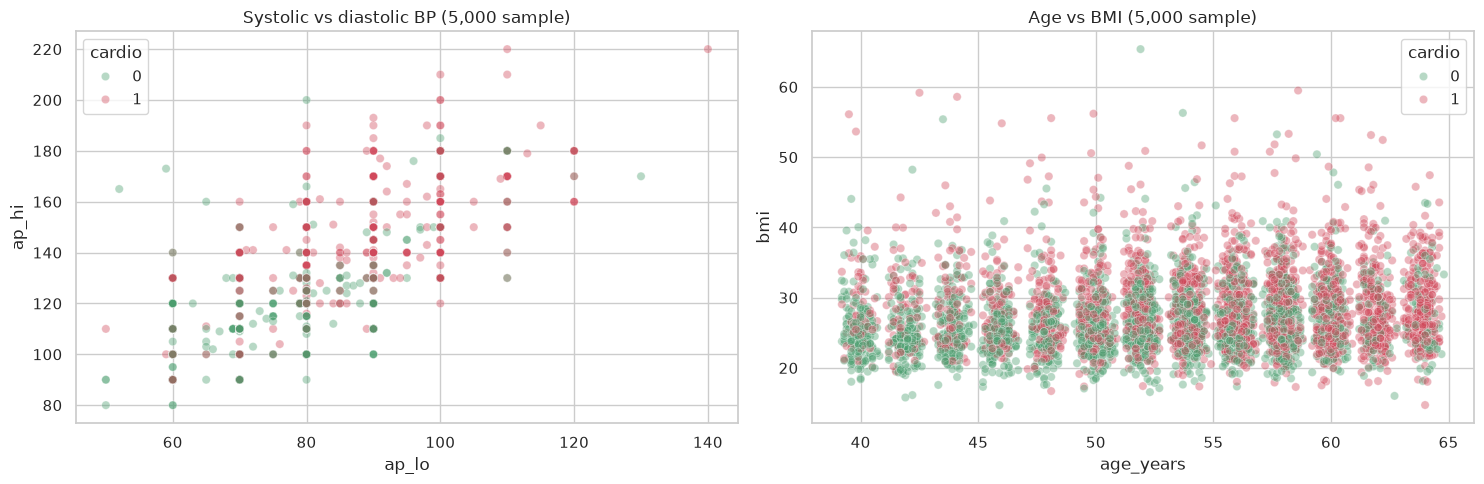

In [16]:
sample = clean_df.sample(5000, random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=sample, x="ap_lo", y="ap_hi", hue=TARGET, alpha=0.4, ax=axes[0], palette=PALETTE)
axes[0].set_title("Systolic vs diastolic BP (5,000 sample)")
sns.scatterplot(data=sample, x="age_years", y="bmi", hue=TARGET, alpha=0.4, ax=axes[1], palette=PALETTE)
axes[1].set_title("Age vs BMI (5,000 sample)")
save("06_scatter")

### 4.6 Correlation matrix

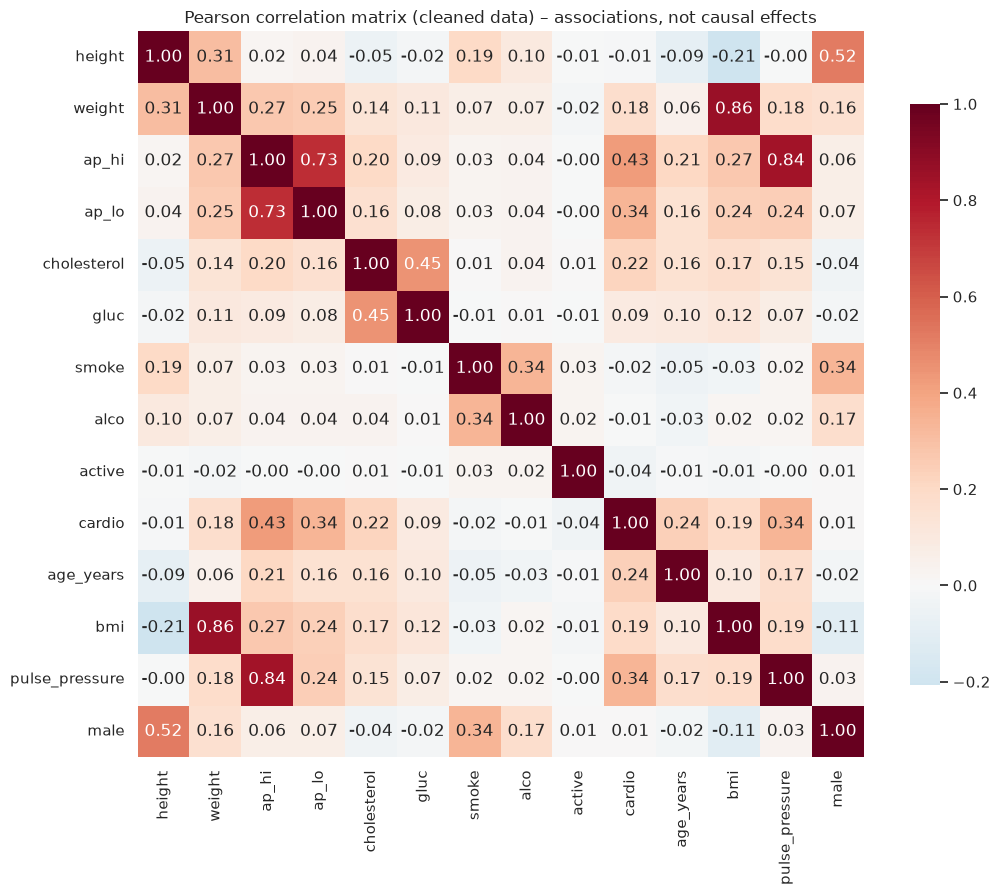

ap_hi             0.428
ap_lo             0.340
pulse_pressure    0.337
age_years         0.239
cholesterol       0.221
bmi               0.190
weight            0.180
gluc              0.090
active           -0.038
smoke            -0.016
height           -0.012
alco             -0.009
male              0.007
Name: cardio, dtype: float64

In [17]:
corr = clean_df.drop(columns="profile_id").corr(numeric_only=True)
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True, cbar_kws={"shrink": .8})
plt.title("Pearson correlation matrix (cleaned data) – associations, not causal effects")
save("07_correlation")
corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3)

### 4.7 Statistical tests of association (supporting RQ1–RQ3)

In [18]:
rows = []
n = len(clean_df)
for c in ["cholesterol", "gluc", "male", "smoke", "alco", "active"]:
    table = pd.crosstab(clean_df[c], clean_df[TARGET])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    rows.append({"feature": c, "test": "chi-square", "statistic": chi2, "p_value": p,
                 "effect size": np.sqrt(chi2 / (n * (min(table.shape) - 1))), "effect measure": "Cramér's V"})
pos, neg = clean_df[clean_df[TARGET] == 1], clean_df[clean_df[TARGET] == 0]
for c in ["age_years", "bmi", "ap_hi", "ap_lo", "pulse_pressure", "height", "weight"]:
    u, p = stats.mannwhitneyu(pos[c], neg[c])
    rows.append({"feature": c, "test": "Mann-Whitney U", "statistic": u, "p_value": p,
                 "effect size": 2 * u / (len(pos) * len(neg)) - 1, "effect measure": "rank-biserial r"})
tests = pd.DataFrame(rows)
tests["significant (p<0.05)"] = tests.p_value < 0.05
tests.round(4)

,feature,test,statistic,p_value,effect size,effect measure,significant (p<0.05)
0,cholesterol,chi-square,3.362244e+03,0.0000,0.2214,Cramér's V,True
1,gluc,chi-square,5.796553e+02,0.0000,0.0919,Cramér's V,True
2,male,chi-square,3.487200e+00,0.0618,0.0071,Cramér's V,False
3,smoke,chi-square,1.824890e+01,0.0000,0.0163,Cramér's V,True
4,alco,chi-square,4.933800e+00,0.0263,0.0085,Cramér's V,True
5,active,chi-square,9.716450e+01,0.0000,0.0376,Cramér's V,True
6,age_years,Mann-Whitney U,7.480007e+08,0.0000,0.2723,rank-biserial r,True
7,bmi,Mann-Whitney U,7.217036e+08,0.0000,0.2276,rank-biserial r,True
8,ap_hi,Mann-Whitney U,8.832948e+08,0.0000,0.5025,rank-biserial r,True
9,ap_lo,Mann-Whitney U,8.121622e+08,0.0000,0.3815,rank-biserial r,True


## Task 5 – Machine Learning Models and Performance Evaluation

### 5a Model selection and justification
| Model | Why it was chosen |
|---|---|
| **Logistic Regression** | A baseline for binary classification. It is interpretable: its coefficients (odds ratios) show the direction and size of each risk factor's effect. |
| **Random Forest** | An ensemble of decision trees that captures non-linear effects and interactions (for example age × blood pressure). It is robust to outliers and gives feature importances. |
| **Neural Network (MLP)** | A flexible non-linear model that suits a large dataset (~68k rows). It is the least interpretable of the three, which lets us test whether the extra complexity is worth it. |

A **dummy classifier** (always predicts the training prevalence) is included as a reference point that any useful model must beat.

SVM was not chosen because kernel SVM training scales roughly quadratically with the number of samples, which makes it impractical to tune with cross-validation on ~55k training rows.

### 5b Data splitting
An 80/20 **stratified, group-aware** train/test split (`StratifiedGroupKFold`). Records with an identical predictor profile share a group, so the same inputs can never appear in both the training and the test set. The test set is held out and used **once**, after all tuning is finished. Tuning and robustness checks use **5-fold stratified group cross-validation** on the training set only.

In [19]:
FEATURES = ["age_years", "male", "height", "weight", "bmi", "ap_hi", "ap_lo", "pulse_pressure",
            "cholesterol", "gluc", "smoke", "alco", "active"]
X, y, groups = clean_df[FEATURES], clean_df[TARGET], clean_df["profile_id"]

outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(outer.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]

assert set(g_train).isdisjoint(groups.iloc[test_idx]), "a predictor profile leaked across train/test"
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

print("Train:", X_train.shape, " Test:", X_test.shape, f" (test share {len(test_idx) / len(X):.1%})")
print("Train target balance:", round(y_train.mean(), 3), " Test:", round(y_test.mean(), 3))

Train: (54867, 13)  Test: (13716, 13)  (test share 20.0%)
Train target balance: 0.495  Test: 0.495


### 5c Model training and hyperparameter tuning

In [20]:
searches = {
    "Logistic Regression": GridSearchCV(
        Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=2000, random_state=SEED))]),
        {"clf__C": [0.001, 0.01, 0.1, 1, 10], "clf__penalty": ["l1", "l2"], "clf__solver": ["liblinear"]},
        cv=cv, scoring="roc_auc", n_jobs=-1),
    "Random Forest": RandomizedSearchCV(
        RandomForestClassifier(random_state=SEED, n_jobs=-1),
        {"n_estimators": [200, 300, 500], "max_depth": [6, 8, 10, 12, None], "min_samples_leaf": [10, 20, 50, 100],
         "max_features": ["sqrt", 0.5]},
        n_iter=12, cv=cv, scoring="roc_auc", n_jobs=2, random_state=SEED),
    "Neural Network (MLP)": RandomizedSearchCV(
        Pipeline([("scaler", StandardScaler()), ("clf", MLPClassifier(max_iter=300, early_stopping=True, random_state=SEED))]),
        {"clf__hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64)], "clf__alpha": [1e-4, 1e-3, 1e-2, 1e-1],
         "clf__learning_rate_init": [1e-3, 3e-3]},
        n_iter=10, cv=cv, scoring="roc_auc", n_jobs=-1, random_state=SEED),
}
best, best_params = {}, {}
for name, s in searches.items():
    s.fit(X_train, y_train, groups=g_train)
    best[name], best_params[name] = s.best_estimator_, s.best_params_
    print(f"{name}: best CV ROC-AUC = {s.best_score_:.4f}\n   best params = {s.best_params_}")

dummy = DummyClassifier(strategy="prior").fit(X_train, y_train)

Logistic Regression: best CV ROC-AUC = 0.7919
   best params = {'clf__C': 0.001, 'clf__penalty': 'l2', 'clf__solver': 'liblinear'}


Random Forest: best CV ROC-AUC = 0.8009
   best params = {'n_estimators': 300, 'min_samples_leaf': 20, 'max_features': 0.5, 'max_depth': 10}


Neural Network (MLP): best CV ROC-AUC = 0.8005
   best params = {'clf__learning_rate_init': 0.003, 'clf__hidden_layer_sizes': (64, 32), 'clf__alpha': 0.1}


### Cross-validation robustness (5-fold, tuned models)

In [21]:
cv_scores = {}
for name, m in best.items():
    r = cross_validate(m, X_train, y_train, groups=g_train, cv=cv, n_jobs=-1,
                       scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
    cv_scores[name] = {k.replace("test_", ""): (v.mean(), v.std()) for k, v in r.items() if k.startswith("test_")}
pd.DataFrame({n: {k: f"{m:.4f} ± {s:.4f}" for k, (m, s) in d.items()} for n, d in cv_scores.items()}).T

,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.7277 ± 0.0026,0.7548 ± 0.0037,0.6659 ± 0.0045,0.7076 ± 0.0030,0.7919 ± 0.0017
Random Forest,0.7349 ± 0.0026,0.7539 ± 0.0046,0.6892 ± 0.0057,0.7201 ± 0.0029,0.8009 ± 0.0018
Neural Network (MLP),0.7346 ± 0.0025,0.7501 ± 0.0051,0.6954 ± 0.0134,0.7216 ± 0.0054,0.8005 ± 0.0018


### 5d Performance evaluation on the held-out test set
The test set is used here for the first and only time.

In [22]:
probas = {name: m.predict_proba(X_test)[:, 1] for name, m in best.items()}
results = {"Dummy (prior)": metrics(y_test, dummy.predict_proba(X_test)[:, 1])}
results.update({name: metrics(y_test, p) for name, p in probas.items()})
results_df = pd.DataFrame(results).T.round(4)
results_df

,Accuracy,Precision,Recall,F1,ROC-AUC,Avg precision,Brier
Dummy (prior),0.5052,0.0000,0.0000,0.0000,0.5000,0.4948,0.2500
Logistic Regression,0.7264,0.7547,0.6622,0.7054,0.7884,0.7707,0.1884
Random Forest,0.7353,0.7547,0.6891,0.7204,0.7980,0.7826,0.1816
Neural Network (MLP),0.7308,0.7329,0.7172,0.7250,0.7971,0.7772,0.1826


In [23]:
for name, m in best.items():
    print(f"=== {name} ===")
    print(classification_report(y_test, m.predict(X_test), target_names=["No CVD", "CVD"], digits=4))

=== Logistic Regression ===
              precision    recall  f1-score   support

      No CVD     0.7047    0.7892    0.7445      6930
         CVD     0.7547    0.6622    0.7054      6786

    accuracy                         0.7264     13716
   macro avg     0.7297    0.7257    0.7250     13716
weighted avg     0.7294    0.7264    0.7252     13716

=== Random Forest ===
              precision    recall  f1-score   support

      No CVD     0.7194    0.7807    0.7488      6930
         CVD     0.7547    0.6891    0.7204      6786

    accuracy                         0.7353     13716
   macro avg     0.7370    0.7349    0.7346     13716
weighted avg     0.7369    0.7353    0.7347     13716

=== Neural Network (MLP) ===
              precision    recall  f1-score   support

      No CVD     0.7288    0.7440    0.7363      6930
         CVD     0.7329    0.7172    0.7250      6786

    accuracy                         0.7308     13716
   macro avg     0.7308    0.7306    0.7306     1

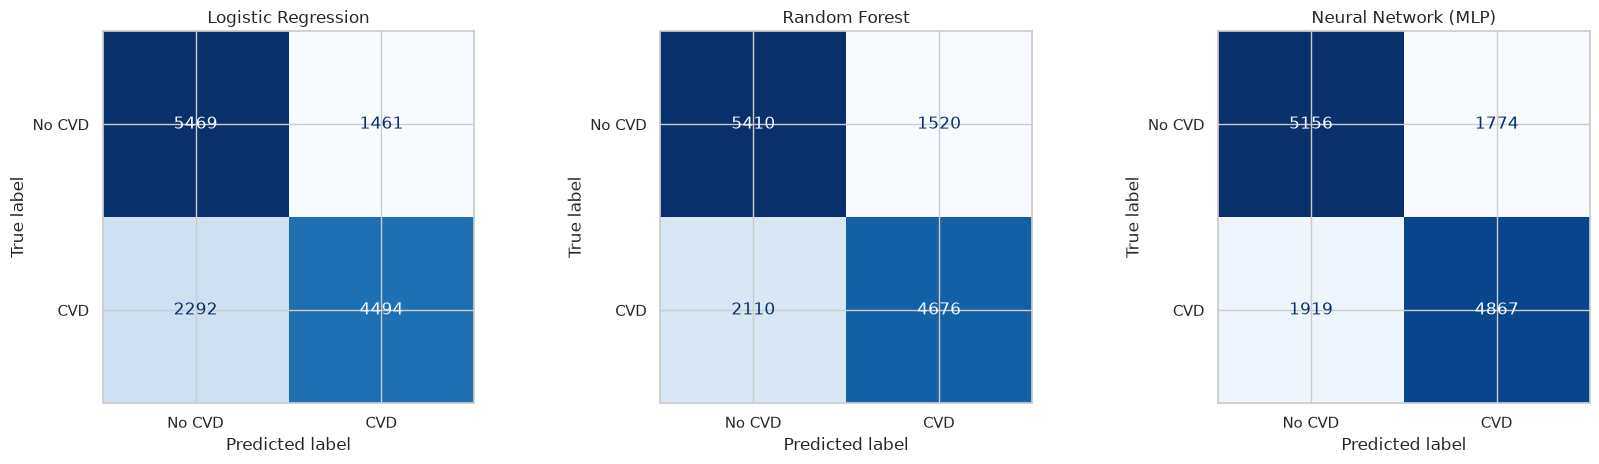

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (name, m) in zip(axes, best.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, display_labels=["No CVD", "CVD"], cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
save("08_confusion_matrices")

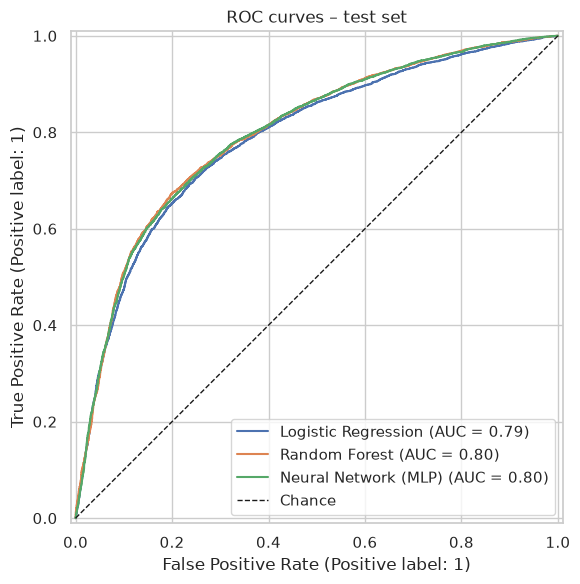

In [25]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, m in best.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
ax.set_title("ROC curves – test set"); ax.legend(loc="lower right")
save("09_roc_curves")

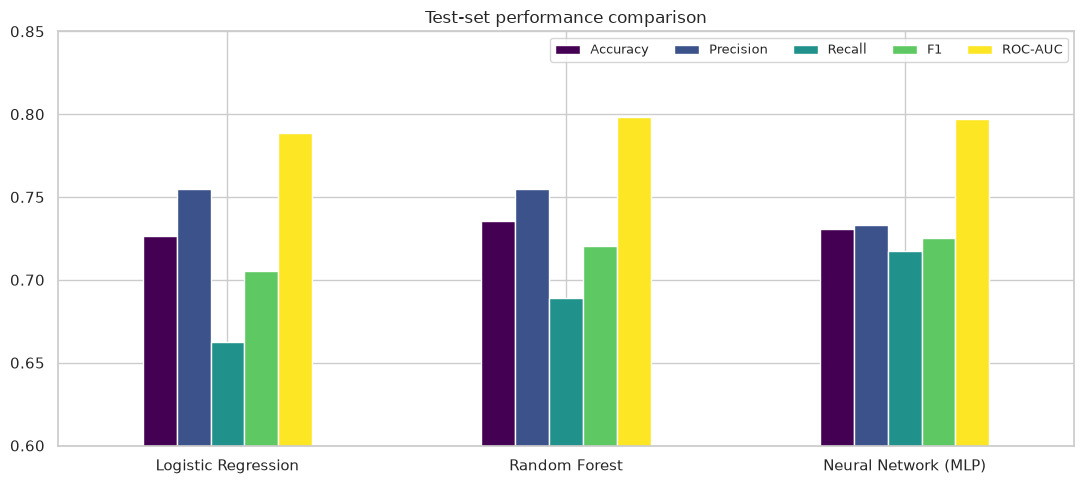

In [26]:
plot_df = results_df.drop(index="Dummy (prior)")[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]]
ax = plot_df.plot(kind="bar", figsize=(11, 5), ylim=(0.6, 0.85), colormap="viridis", rot=0)
ax.set_title("Test-set performance comparison"); ax.legend(loc="upper right", ncol=5, fontsize=9)
save("10_model_comparison")

### Feature importance (RQ1 / RQ4)

,coef (standardised),odds ratio per 1 SD
ap_hi,0.425,1.529
ap_lo,0.361,1.434
age_years,0.320,1.377
pulse_pressure,0.315,1.371
cholesterol,0.293,1.341
active,-0.088,0.916
weight,0.081,1.085
bmi,0.075,1.078
alco,-0.046,0.955
gluc,-0.041,0.960


,Logistic Regression,Random Forest,Neural Network (MLP)
ap_hi,0.0416,0.1417,0.0500
age_years,0.0276,0.0347,0.0342
cholesterol,0.0232,0.0310,0.0355
ap_lo,0.0296,0.0036,0.0321
bmi,0.0012,0.0026,0.0016
pulse_pressure,0.0237,0.0014,0.0255
gluc,0.0006,0.0012,0.0022
active,0.0013,0.0012,0.0014
weight,0.0016,0.0009,0.0024
smoke,0.0005,0.0005,0.0004


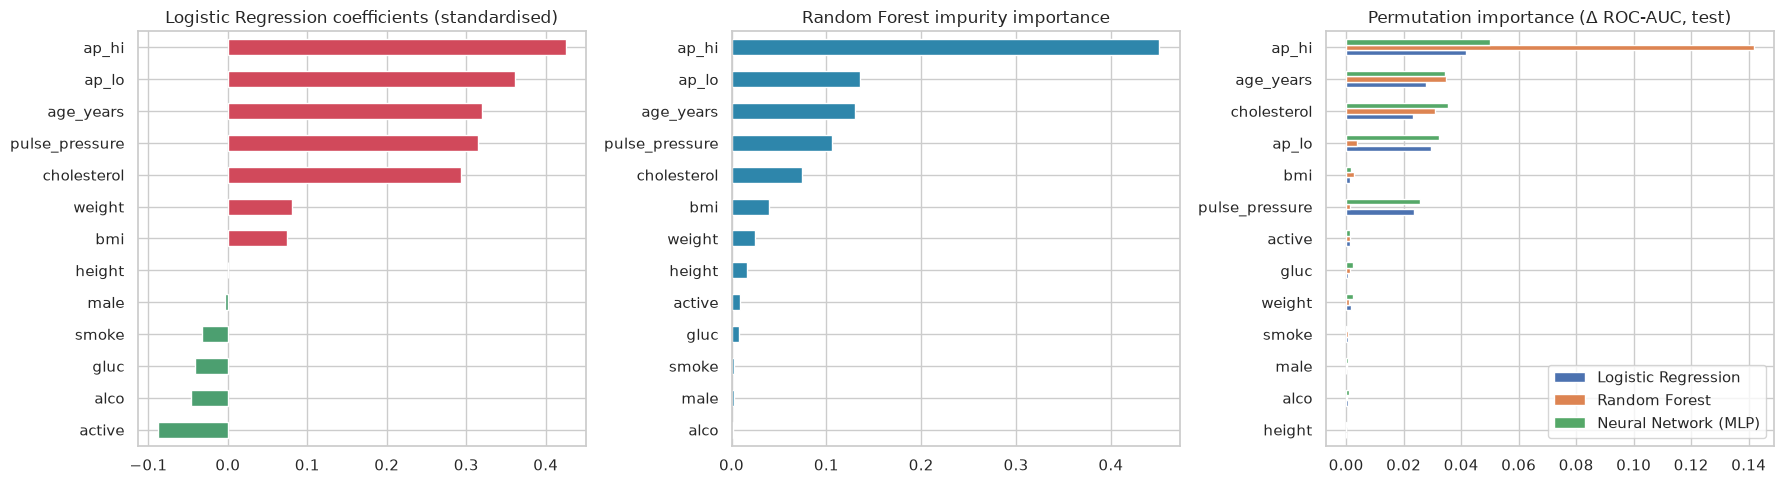

In [27]:
lr = best["Logistic Regression"].named_steps["clf"]
lr_coef = pd.DataFrame({"coef (standardised)": lr.coef_[0], "odds ratio per 1 SD": np.exp(lr.coef_[0])}, index=FEATURES)
lr_coef = lr_coef.reindex(lr_coef["coef (standardised)"].abs().sort_values(ascending=False).index).round(3)
rf_imp = pd.Series(best["Random Forest"].feature_importances_, index=FEATURES).sort_values(ascending=False)
perm = {name: permutation_importance(m, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1).importances_mean
        for name, m in best.items()}
perm_df = pd.DataFrame(perm, index=FEATURES).sort_values("Random Forest", ascending=False).round(4)
display(lr_coef); display(perm_df)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
coef_sorted = lr_coef["coef (standardised)"].sort_values()
coef_sorted.plot.barh(ax=axes[0], color=np.where(coef_sorted > 0, "#d1495b", "#4c9f70"))
axes[0].set_title("Logistic Regression coefficients (standardised)")
rf_imp.sort_values().plot.barh(ax=axes[1], color="#2e86ab"); axes[1].set_title("Random Forest impurity importance")
perm_df.sort_values("Random Forest").plot.barh(ax=axes[2]); axes[2].set_title("Permutation importance (Δ ROC-AUC, test)")
save("11_feature_importance")

### 5e Model comparison and selection

In [28]:
model_rows = results_df.drop(index="Dummy (prior)")
best_name = model_rows["ROC-AUC"].idxmax()
print(model_rows.sort_values("ROC-AUC", ascending=False))
print("\nHighest test ROC-AUC:", best_name)
gap = model_rows.loc[best_name, "ROC-AUC"] - model_rows.loc["Logistic Regression", "ROC-AUC"]
print(f"ROC-AUC advantage over Logistic Regression: {gap:.4f}")

                      Accuracy  Precision  Recall      F1  ROC-AUC  Avg precision   Brier
Random Forest           0.7353     0.7547  0.6891  0.7204   0.7980         0.7826  0.1816
Neural Network (MLP)    0.7308     0.7329  0.7172  0.7250   0.7971         0.7772  0.1826
Logistic Regression     0.7264     0.7547  0.6622  0.7054   0.7884         0.7707  0.1884

Highest test ROC-AUC: Random Forest
ROC-AUC advantage over Logistic Regression: 0.0096


### Save results
Everything needed to reproduce or cite the numbers in the report is written to one JSON file.

In [29]:
run_record = {
    "seed": SEED, "versions": VERSIONS, "plausibility_limits": LIMITS, "exclusions": exclusion_log,
    "split": {"method": "StratifiedGroupKFold (5 folds, first fold = test) grouped by predictor profile",
              "train": len(train_idx), "test": len(test_idx)},
    "selection_metric": "cross-validated ROC-AUC on training data", "threshold": 0.5,
    "best_params": {k: {p: str(v) for p, v in d.items()} for k, d in best_params.items()},
    "cv_mean_std": cv_scores, "test": results, "selected_model": best_name,
}
path = REPORT_DIR / "notebook_results.json"
path.write_text(json.dumps(run_record, indent=2, default=float))
print("Saved", path.relative_to(ROOT))

Saved reports/notebook_results.json


## Task 6 – Interpretation and Conclusion

### Summary of findings against the research questions

**RQ1 – Significant factors.** **Systolic blood pressure** is by far the strongest factor. Its correlation with CVD is r = 0.43, and its rank-biserial effect size is 0.50. CVD prevalence rises from 23% (systolic < 120 mmHg) to 83–86% (≥ 140 mmHg). It is followed by diastolic BP, pulse pressure, **age**, **cholesterol** (43.5% → 59.6% → 76.2% prevalence across levels 1–3), BMI/weight and glucose. All of these are significant at p < 0.001.

**RQ2 – Demographics.** **Age** is strongly associated with CVD. Prevalence rises from 24% (≤ 40 years) to 67% (60–65 years), and each extra standard deviation (~6.8 years) multiplies the odds by about 1.38 in Logistic Regression. **Gender** is *not* significantly associated (49.2% vs 50.0%, χ² p = 0.06).

**RQ3 – Lifestyle.** Physical activity has a small protective association (53.3% prevalence when inactive vs 48.5% when active). Smoking and alcohol show a statistically significant but tiny, *counter-intuitive* negative association (Cramér's V < 0.02). This most likely reflects self-report bias and confounding: smokers in the data are mostly men, and diagnosed patients may have already quit. It should not be read as a causal protective effect.

**RQ4 – Predictive contribution.** All three models agree. Permutation importance ranks `ap_hi` first, then age, cholesterol and diastolic BP. The lifestyle variables contribute almost nothing to predictive power. The strongly regularised Logistic Regression (C = 0.001) spreads weight across the three correlated blood pressure variables (systolic, diastolic, pulse pressure), so their importances should be read together.

**RQ5 – Model performance.** All tuned models reach ~73–74% accuracy and ~0.79–0.80 ROC-AUC on the held-out, group-separated test set, far above the dummy baseline (accuracy 0.505, ROC-AUC 0.500). **Random Forest** is best (accuracy 0.735, ROC-AUC 0.798, best-calibrated with Brier 0.182). The MLP is essentially tied (ROC-AUC 0.797) and has the highest recall (0.717) and F1 (0.725). Logistic Regression is about 1 percentage point lower (ROC-AUC 0.788). The cross-validation standard deviations (0.002–0.013) show that results are stable.

**Model choice.** Random Forest is selected as the final model for its best accuracy and AUC and its ability to model non-linear BP–age interactions. Because the gain over Logistic Regression is small, **Logistic Regression remains a strong choice when explainability matters most**, for example when giving clinicians odds ratios.

### Implications
- Blood pressure control, cholesterol management and weight management are the most actionable prevention targets. This is consistent with clinical guidelines.
- A simple model built on routinely collected measurements (BP, age, cholesterol, weight) can serve as a low-cost **screening tool** to prioritise patients for further testing. It is not a diagnostic tool.
- Recall (~0.69 for Random Forest) means roughly 1 in 3 CVD cases is missed at the default 0.5 threshold. For screening, the decision threshold should be lowered to favour recall.

### Limitations
- About 2% of records were removed because of impossible BP and anthropometric values, which raises concerns about the quality of data entry.
- Lifestyle variables are binary and self-reported. Cholesterol and glucose are only 3-level categories, not laboratory values.
- The data source, population and the definition of "CVD" are not documented, which limits generalisability. The data is cross-sectional, so associations are not causal.
- The performance ceiling (~73–74% accuracy) suggests that important predictors (family history, medication, lipid profile, ECG) are missing.

### Future research
- Add richer clinical variables, use longitudinal data and validate externally on a different population.
- Try gradient-boosting models (XGBoost, LightGBM, CatBoost), threshold tuning and probability calibration.
- Use SHAP explanations for patient-level interpretability, and apply clustering to identify risk phenotypes.